# Energy confluence at the nanoscale
The objective of this Notebook is to illustrate the confluence of multiple energy scales for different physical effects at the nanoscale and how this naturally leads to softmatter, and thermal and quantum fluctuations.  
For physical constants we will use by default scipython constants (always check CODATA standard values, for example here: https://physics.nist.gov/ )

In [11]:
#Import python numerical libraries
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as ct

### Thermal energy at ambient temperature in different units and energy scales

In [12]:
T=300 #Temperature in Kelvin
TE=ct.k*T #Thermal energy in SI
TE_eV=TE/ct.e #Thermal Energy in eV
print(f"Thermal Energy at {T}K:")
print(f"{TE:.2e} J = {TE*ct.N_A/1000:.2e} kJ/mol ={TE_eV:.2e} eV")

Thermal Energy at 300K:
4.14e-21 J = 2.49e+00 kJ/mol =2.59e-02 eV


In [13]:
Hb=20000/ct.N_A #Typical energy of a molecular hydrogen bond: 20 kJ/mol
E_atp=12000*ct.calorie/ct.N_A #Typical Energy of ATP hydrolysis: 12 kcal/mol
print(f"Some energies compared with thermal energy:")
print(f"Typical hydrogen bond: {Hb/TE:.1f}kT")
print(f"ATP hydrolysis: {E_atp/TE:.1f}kT")

Some energies compared with thermal energy:
Typical hydrogen bond: 8.0kT
ATP hydrolysis: 20.1kT


In [14]:
#Thermal work and thermal force: force producing a d=1nm displacement 
d=1E-9
F=TE/d
print(f"F= {F:.1e} N")

F= 4.1e-12 N


## Energy associated to different mechanisms

### Bending energy for a rod
Assuming a cylinder of length $L$ bended to make a semi-circle of radius $L=\pi R$ of a material with Young modulus $Y$ (typically 0.1 GPa -1 GPa for soft matter), the bending energy is:
$$
E_b=\frac{Y\pi^3R^4}{8L}=\frac{Y\pi^3R^3}{8\alpha}
$$
(where $\alpha=L/R$ is the aspect ratio).

In [15]:
#Numerical example of a rod as a function of radius (fixed aspect ratio) 
Y=0.1E9 # Young Modulus 0.1 GPa - 1 GPa
rc=1E-9
alpha=100
Eb_example=Y*(np.pi**3)*(rc**3.0)/(8*alpha)
print(Eb_example/TE)

0.9357397825316157


### Ionic interaction in water
Binding electrostatic energy (Coulomb) between two oppositely charged spheres (ions, nanoparticles,...) of diameter $d$ in water ($\epsilon_r=80$):
$$
E_{ionic}=\frac{e^2}{4\pi\epsilon_0\epsilon_rd}
$$

In [16]:
#Example for the case of d=1 nm
d=1E-9
epsr=80
Eion_ex=(ct.e**2)/(4*np.pi*ct.epsilon_0*epsr*d*TE)
print(Eion_ex)

0.6962539449377173


### Energy of one electron in a nanometric box 
The quantum mechanical energy for a particle in a box is given by: 
$$
E=\frac{n^2h^2}{8mL^2}
$$
see for example
https://chem.libretexts.org/Courses/Pacific_Union_College/Quantum_Chemistry/03%3A_The_Schrodinger_Equation_and_a_Particle_in_a_Box/3.05%3A_The_Energy_of_a_Particle_in_a_Box_is_Quantized 

So for an electron at the ground state in a nanometric box it is given by:

In [17]:
L=1E-9 #one nanometer
Ebox_ex=ct.h**2/(8*ct.electron_mass*ct.e*L**2) #Energy in eV
print("Energy in eV=",Ebox_ex)
print("Energy box/kT=",Ebox_ex/TE_eV)

Energy in eV= 0.3760301621048726
Energy box/kT= 14.54549610131803


## A comparison plot of all energy scales
**Exercise: Create a function for each energy (bend, ionic, box) and plot them together in a log-log plot**  
The idea is to make a plot of all these energies as a function of the characteristic size of the system as in Phillips & Quake article.  
Given the diversity of scales, the plot has to be logarithmic.

*Hint:* A way to create logarithmic spacing is using numpy.geomspace function:  
numpy.geomspace(start, stop, num=50, endpoint=True, dtype=None, axis=0)  
https://www.geeksforgeeks.org/python/how-to-create-a-list-of-uniformly-spaced-numbers-using-a-logarithmic-scale-with-python/


In [21]:
# logarithmic spacing https://#www.geeksforgeeks.org/python/how-to-create-a-list-of-uniformly-spaced-numbers-using-a-logarithmic-scale-with-python/
x=np.geomspace(0.001, 10000, 20, endpoint = True)
print(x)

[1.00000000e-03 2.33572147e-03 5.45559478e-03 1.27427499e-02
 2.97635144e-02 6.95192796e-02 1.62377674e-01 3.79269019e-01
 8.85866790e-01 2.06913808e+00 4.83293024e+00 1.12883789e+01
 2.63665090e+01 6.15848211e+01 1.43844989e+02 3.35981829e+02
 7.84759970e+02 1.83298071e+03 4.28133240e+03 1.00000000e+04]


In [29]:
#Bending energy function
Eb=Eb_example*(x**3.0)/TE
print(Eb)
#ionic energy
Eion=Eion_ex/x
#quantum ebox
Ebox=(Ebox_ex/TE_eV)/(x**2.0)

[9.35739783e-10 1.19238980e-08 1.51943249e-07 1.93617482e-06
 2.46721914e-05 3.14391563e-04 4.00621305e-03 5.10501707e-02
 6.50519556e-01 8.28940798e+00 1.05629852e+02 1.34601479e+03
 1.71519297e+04 2.18562750e+05 2.78509045e+06 3.54897109e+07
 4.52236509e+08 5.76273671e+09 7.34331124e+10 9.35739783e+11]


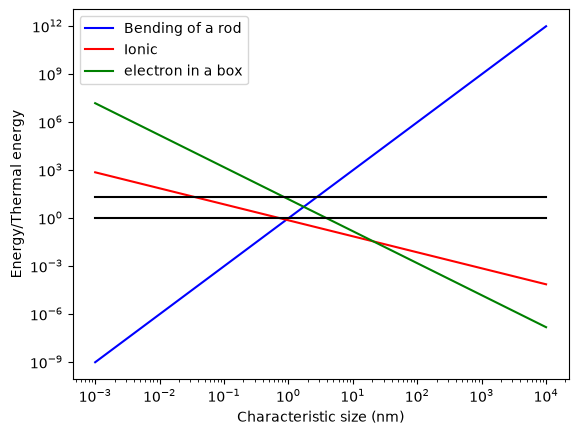

In [33]:
plt.plot(x,Eb,label="Bending of a rod",color="blue")
plt.plot(x,Eion,label="Ionic",color="red")
plt.plot(x,Ebox,label="electron in a box",color="green")
plt.plot(x,np.ones(len(x)), color="black")
plt.plot(x,(E_atp/TE)*np.ones(len(x)),color="black")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Characteristic size (nm)")
plt.ylabel("Energy/Thermal energy")
plt.legend()
plt.show()